# Restaurant Dish Sales 2018-2019: Sales Analysis

This notebook repeats the Excel pivot-table analysis in Python. It validates and cleans the raw sales log, then answers 10 business questions with a chart, a finding and a recommendation for each.

**Data:** one row per sales transaction: salesperson, product category, region (Ghana regions: Ashanti, Greater Accra, Oti, Savannah), customer, date and sales value. There are **no cost, profit or discount columns**, so this analysis covers revenue, volume and mix, not margin.

## Business questions
1. How much did the restaurant sell over 2018-2019, and did sales grow?
2. Is there a reliable monthly seasonal pattern?
3. Which dishes drive revenue, and is that price or volume?
4. Which dishes grew or shrank from 2018 to 2019?
5. Which regions sell the most, and how did they change?
6. What explains the Oti decline? Which salespeople grew or declined?
7. How dependent are we on a few customers?
8. Who are the top salespeople, and what makes them top?
9. What size are typical orders, and where does the money come from?
10. Which days of the week do orders come in?

## 1. Setup

In [1]:
# Import the libraries we need
import pandas as pd
import matplotlib.pyplot as plt

# Chart style used for every chart in this notebook
MAIN = "#B85042"      # terracotta - main bar colour
HIGHLIGHT = "#5A1E16" # dark red - used to highlight one bar
GREY = "#C9C3BD"      # neutral grey - for comparison bars
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 11
plt.rcParams["axes.formatter.limits"] = (-9, 9)  # show 1400000, not 1.4e6

# Folder where charts are saved (images/ at the project root)
IMG = "../images/"

## 2. Load the raw data
We read the sales table straight from the original workbook in `data/raw/` (the file is never changed).

In [2]:
# Read the sales table from the original Excel file
df_raw = pd.read_excel("../data/raw/Project1_PivotTables_Sales.xlsx", sheet_name="Data", header=7, usecols="B:G", nrows=909)

# Look at the first 5 rows
df_raw.head()

,Salesperson,Product Category,Region,Customer,Date,Total Sales
0,"Stuart, Jill",Vegetarian Dishes,Oti,Elton John,2018-01-06,3068.55
1,"Fog, Londong",Fish Meals,Ashanti,Kwaku Mason,2018-01-06,681.90
2,"Haveria, Luiz",Seafood,Greater Accra,Clifford Quist,2018-01-07,559.93
3,"Fog, Londong",Beef Meals,Ashanti,Clifford Quist,2018-01-08,506.85
4,"Hines, Zach",Seafood,Ashanti,Elton John,2018-01-08,959.88


In [3]:
# How many rows and columns?
print(df_raw.shape)

# Column types
df_raw.dtypes

(909, 6)


Salesperson                    str
Product Category               str
Region                         str
Customer                       str
Date                datetime64[us]
Total Sales                float64
dtype: object

## 3. Validate the data
Check for blanks, duplicates, bad dates, impossible values and inconsistent category labels before trusting any number.

In [4]:
# Count blank cells in each column
df_raw.isna().sum()

Salesperson         0
Product Category    0
Region              0
Customer            0
Date                0
Total Sales         0
dtype: int64

In [5]:
# Count rows that are exact duplicates of another row
df_raw.duplicated().sum()

np.int64(0)

In [6]:
# Check every Date is a real date, and see the date range
print(pd.to_datetime(df_raw['Date'], errors='coerce').isna().sum(), 'bad dates')
print(df_raw['Date'].min(), 'to', df_raw['Date'].max())

0 bad dates
2018-01-06 00:00:00 to 2019-12-30 00:00:00


In [7]:
# Sales values: any zero or negative?
print(df_raw['Total Sales'].describe())
print((df_raw['Total Sales'] <= 0).sum(), 'rows with zero or negative sales')

count      909.000000
mean      3115.143751
std       3085.138787
min         79.990000
25%        879.890000
50%       2045.700000
75%       4091.400000
max      15999.000000
Name: Total Sales, dtype: float64
0 rows with zero or negative sales


In [8]:
# Category labels - repr() shows hidden spaces at the end of a label
df_raw['Product Category'].map(repr).value_counts()

Product Category
'Fish Meals '           205
'Pasta Dishes'          182
'Beef Meals'            181
'Seafood'               176
'Vegetarian Dishes '    165
Name: count, dtype: int64

In [9]:
# The other text columns
for col in ['Salesperson', 'Region', 'Customer']:
    print(df_raw[col].value_counts(), '\n')

Salesperson
Stuart, Jill          119
Haveria, Luiz         100
Read, Tira             96
Smith, Bob             84
Dede, Amakye           78
Fog, Londong           73
Azpilecueta, Moses     71
Barkley, Ross          65
Hines, Zach            59
Milner, James          57
Temple, Cheryl         55
Tall, Liz              52
Name: count, dtype: int64 

Region
Oti              310
Savannah         291
Greater Accra    176
Ashanti          132
Name: count, dtype: int64 

Customer
Elton John        193
Kwaku Mason       188
Clifford Quist    181
Fisher Mills      175
Sharon Sticks     172
Name: count, dtype: int64 



**Validation result:** 909 rows, 0 blanks, 0 exact duplicates, 0 bad dates and 0 zero or negative sales. One issue: **370 rows** have a trailing space in the product name (`'Fish Meals '`, `'Vegetarian Dishes '`). Excel hides this, but it would break lookups and joins, so we trim it.

## 4. Clean the data and add helper columns

In [10]:
# Work on a copy so the raw data stays as it was
df = df_raw.copy()

# Use short, simple column names
df = df.rename(columns={"Total Sales": "Sales", "Product Category": "Product"})

# Remove hidden spaces at the start/end of text values
for col in ["Salesperson", "Product", "Region", "Customer"]:
    df[col] = df[col].str.strip()

# Round sales to cents (removes tiny floating-point noise like 3068.5499999)
df["Sales"] = df["Sales"].round(2)

# Date parts for grouping
df["Year"] = df["Date"].dt.year
df["MonthNum"] = df["Date"].dt.month
df["Month"] = df["Date"].dt.strftime("%b")
df["Quarter"] = "Q" + df["Date"].dt.quarter.astype(str)
df["Weekday"] = df["Date"].dt.strftime("%a")

df["Product"].value_counts()

Product
Fish Meals           205
Pasta Dishes         182
Beef Meals           181
Seafood              176
Vegetarian Dishes    165
Name: count, dtype: int64

Every sales value is a whole multiple of one price per product (for example Seafood = 79.99 x 1 to 20). So we can recover the **unit price** and the **number of dishes (Units)** in each order.

In [11]:
# The smallest sale of each product is the price of one dish
unit_price = df.groupby("Product")["Sales"].min()
print(unit_price)

# Units = sales / unit price
df["UnitPrice"] = df["Product"].map(unit_price)
df["Units"] = (df["Sales"] / df["UnitPrice"]).round().astype(int)

# Check: are all units whole numbers between 1 and 20?
print("Whole numbers:", ((df["Sales"] / df["UnitPrice"]) - df["Units"]).abs().max() < 0.000001)
print("Units range:", df["Units"].min(), "to", df["Units"].max())

Product
Beef Meals           168.95
Fish Meals           340.95
Pasta Dishes         799.95
Seafood               79.99
Vegetarian Dishes    340.95
Name: Sales, dtype: float64
Whole numbers: True
Units range: 1 to 20


In [12]:
# Add an order ID and save the clean data for Excel / other tools
df.insert(0, "OrderID", range(1, len(df) + 1))
df.to_csv("../data/processed/Project1_sales_clean_final.csv", index=False)
df.head()

,OrderID,Salesperson,Product,Region,Customer,Date,Sales,Year,MonthNum,Month,Quarter,Weekday,UnitPrice,Units
0,1,"Stuart, Jill",Vegetarian Dishes,Oti,Elton John,2018-01-06,3068.55,2018,1,Jan,Q1,Sat,340.95,9
1,2,"Fog, Londong",Fish Meals,Ashanti,Kwaku Mason,2018-01-06,681.90,2018,1,Jan,Q1,Sat,340.95,2
2,3,"Haveria, Luiz",Seafood,Greater Accra,Clifford Quist,2018-01-07,559.93,2018,1,Jan,Q1,Sun,79.99,7
3,4,"Fog, Londong",Beef Meals,Ashanti,Clifford Quist,2018-01-08,506.85,2018,1,Jan,Q1,Mon,168.95,3
4,5,"Hines, Zach",Seafood,Ashanti,Elton John,2018-01-08,959.88,2018,1,Jan,Q1,Mon,79.99,12


### Reconcile with the original pivot tables
The cleaned data must give the same totals as the original Excel pivots.

In [13]:
# Grand total and product totals - compare with the original workbook's pivot tables
print("Total sales:", round(df["Sales"].sum(), 2))
df.groupby("Product")["Sales"].sum().round(2)

Total sales: 2831665.67


Product
Beef Meals            272347.40
Fish Meals            618824.25
Pasta Dishes         1343116.05
Seafood               119025.12
Vegetarian Dishes     478352.85
Name: Sales, dtype: float64

Total = **2,831,665.67**, the same as the original pivot Grand Total. Cleaning changed labels only, not values.

## 5. Business questions

### Q1. How much did the restaurant sell over 2018-2019, and did sales grow?

In [14]:
# Headline KPIs
print("Total sales:", round(df["Sales"].sum(), 2))
print("Orders:", len(df))
print("Dishes sold:", df["Units"].sum())
print("Average order value:", round(df["Sales"].mean(), 2))

Total sales: 2831665.67
Orders: 909
Dishes sold: 7997
Average order value: 3115.14


In [15]:
# Sales, orders and average order value by year
by_year = df.groupby("Year").agg(Sales=("Sales", "sum"), Orders=("Sales", "count"))
by_year["AvgOrder"] = by_year["Sales"] / by_year["Orders"]
by_year["Growth_%"] = by_year["Sales"].pct_change() * 100
by_year.round(1)

,Sales,Orders,AvgOrder,Growth_%
Year,,,,
2018,1389110.8,452,3073.3,NaN
2019,1442554.9,457,3156.6,3.8


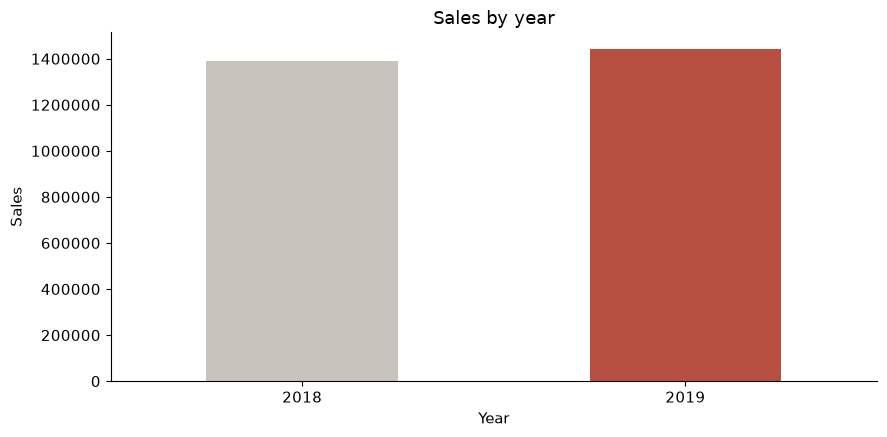

In [16]:
by_year["Sales"].plot(kind="bar", color=[GREY, MAIN])
plt.title("Sales by year")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG + "q1_sales_by_year.png", dpi=150)
plt.show()

**Finding:** Sales totalled 2.83M from 909 orders (7,997 dishes). 2019 sales were 1.44M vs 1.39M in 2018 (+3.8%). Order count barely moved (452 to 457); growth came from a higher average order (3,073 to 3,157).

**Recommendation:** Growth is slow and comes from bigger orders, not more orders. Set a 2020 target for order count (for example +5%) and track orders and average order value as separate KPIs.

### Q2. Is there a reliable monthly seasonal pattern?

In [17]:
# Month totals with both years added together (what the original dashboard shows)
month_order = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
df.groupby("Month")["Sales"].sum().reindex(month_order).round(0)

Month
Jan    263177.0
Feb    247069.0
Mar    176984.0
Apr    222087.0
May    258159.0
Jun    252743.0
Jul    213941.0
Aug    204312.0
Sep    234872.0
Oct    204506.0
Nov    272237.0
Dec    281578.0
Name: Sales, dtype: float64

In [18]:
# Now split by year: one column per year
by_month_year = df.pivot_table(index="Month", columns="Year", values="Sales", aggfunc="sum").reindex(month_order)
by_month_year.round(0)

Year,2018,2019
Month,,
Jan,78303.0,184874.0
Feb,153621.0,93448.0
Mar,90836.0,86149.0
Apr,103070.0,119017.0
May,95315.0,162844.0
Jun,139803.0,112939.0
Jul,135693.0,78248.0
Aug,95190.0,109122.0
Sep,127949.0,106924.0


In [19]:
# Do the two years follow the same pattern? (1 = identical shape, 0 = no relation, negative = opposite)
print("Correlation 2018 vs 2019:", round(by_month_year[2018].corr(by_month_year[2019]), 2))

# Which months are above that year's average in BOTH years?
above = by_month_year > by_month_year.mean()
above.all(axis=1)

Correlation 2018 vs 2019: -0.38


Month
Jan    False
Feb    False
Mar    False
Apr    False
May    False
Jun    False
Jul    False
Aug    False
Sep    False
Oct    False
Nov     True
Dec     True
dtype: bool

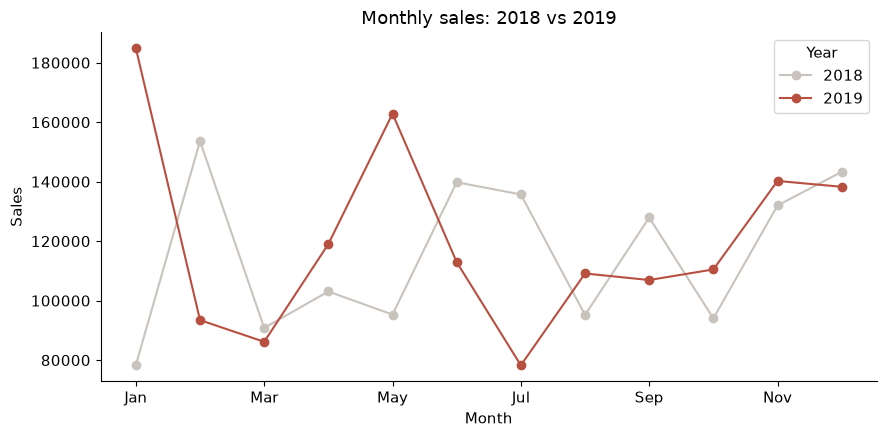

In [20]:
by_month_year.plot(kind="line", marker="o", color=[GREY, MAIN])
plt.title("Monthly sales: 2018 vs 2019")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig(IMG + "q2_month_by_year.png", dpi=150)
plt.show()

**Finding:** No. The original dashboard adds 2018 and 2019 together by month, which suggests a December peak (281.6K) and a March dip (177.0K). Split by year, the months do not repeat: January was 78.3K in 2018 but 184.9K in 2019, and the correlation between the two years' monthly patterns is -0.38. Nov and Dec are the only months above average in both years (275.3K in 2018, 278.5K in 2019).

**Recommendation:** Do not plan staffing or stock from a single 'seasonality' chart that merges years. Plan month by month from a rolling forecast, and only lock in a Nov-Dec uplift, the one pattern seen in both years.

### Q3. Which dishes drive revenue, and is that price or volume?

In [21]:
# Revenue share vs share of dishes sold, per product
prod = df.groupby("Product").agg(Sales=("Sales", "sum"), Units=("Units", "sum"))
prod["Sales_%"] = prod["Sales"] / prod["Sales"].sum() * 100
prod["Units_%"] = prod["Units"] / prod["Units"].sum() * 100
prod["UnitPrice"] = unit_price
prod = prod.sort_values("Sales", ascending=False)
prod.round(1)

,Sales,Units,Sales_%,Units_%,UnitPrice
Product,,,,,
Pasta Dishes,1343116.0,1679,47.4,21.0,800.0
Fish Meals,618824.2,1815,21.9,22.7,341.0
Vegetarian Dishes,478352.8,1403,16.9,17.5,341.0
Beef Meals,272347.4,1612,9.6,20.2,169.0
Seafood,119025.1,1488,4.2,18.6,80.0


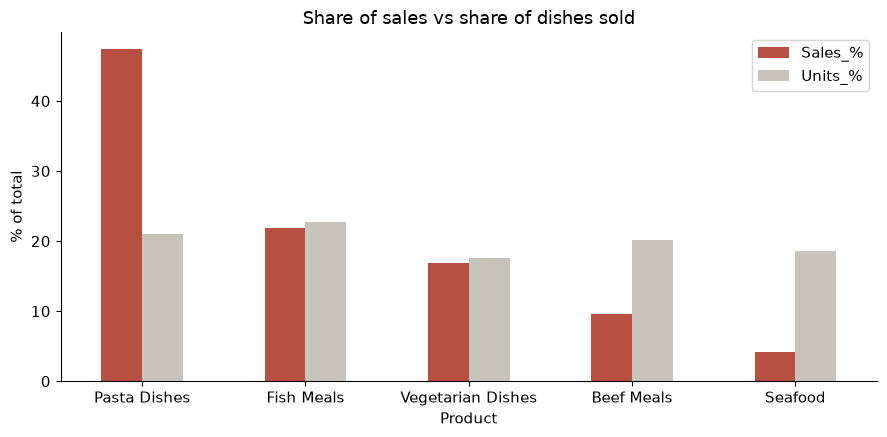

In [22]:
prod[["Sales_%", "Units_%"]].plot(kind="bar", color=[MAIN, GREY])
plt.title("Share of sales vs share of dishes sold")
plt.ylabel("% of total")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG + "q3_product_rev_vs_units.png", dpi=150)
plt.show()

**Finding:** Pasta Dishes earn 47.4% of sales (1.34M) but only 21.0% of dishes sold. It is price-driven: a pasta dish sells at 799.95, vs 79.99 for Seafood. Seafood sells 18.6% of dishes but brings only 4.2% of sales.

**Recommendation:** Protect pasta availability and quality first; it is nearly half the business. Use Seafood as a low-price add-on or review its price, since its volume is not turning into revenue.

### Q4. Which dishes grew or shrank from 2018 to 2019?

In [23]:
# Sales by product for each year, and the growth %
prod_year = df.pivot_table(index="Product", columns="Year", values="Sales", aggfunc="sum")
prod_year["Growth_%"] = (prod_year[2019] / prod_year[2018] - 1) * 100
prod_year.sort_values("Growth_%", ascending=False).round(1)

Year,2018,2019,Growth_%
Product,,,
Beef Meals,121306.1,151041.3,24.5
Pasta Dishes,643959.8,699156.3,8.6
Fish Meals,312651.2,306173.1,-2.1
Vegetarian Dishes,244802.1,233550.8,-4.6
Seafood,66391.7,52633.4,-20.7


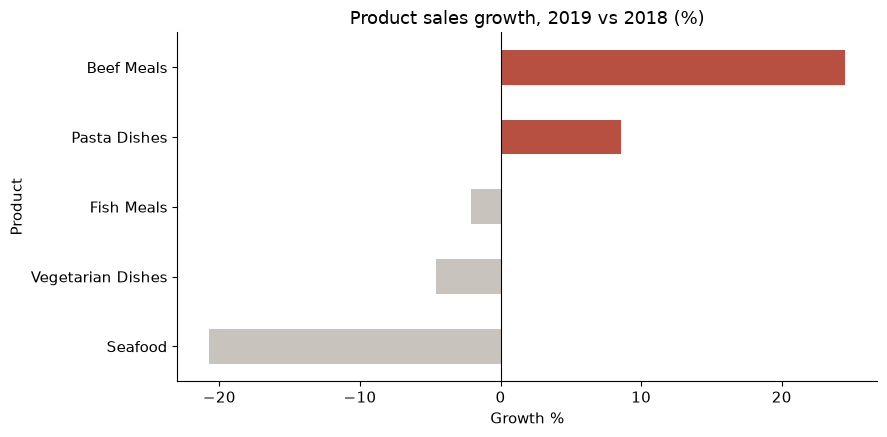

In [24]:
growth = prod_year["Growth_%"].sort_values()
colors = [MAIN if g > 0 else GREY for g in growth]
growth.plot(kind="barh", color=colors)
plt.title("Product sales growth, 2019 vs 2018 (%)")
plt.xlabel("Growth %")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig(IMG + "q4_product_yoy.png", dpi=150)
plt.show()

**Finding:** Beef Meals grew fastest (+24.5%) and Pasta Dishes grew +8.6%. Seafood fell 20.7%, Vegetarian 4.6% and Fish 2.1%.

**Recommendation:** Put promotion budget behind Beef and Pasta, which are already growing. Run a short review of the Seafood menu (price, portion, visibility) before cutting it.

### Q5. Which regions sell the most, and how did they change?

In [25]:
# Region share of total sales
region = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
(region / region.sum() * 100).round(1)

Region
Savannah         35.3
Oti              33.6
Greater Accra    16.2
Ashanti          15.0
Name: Sales, dtype: float64

In [26]:
# Region sales by year and growth
region_year = df.pivot_table(index="Region", columns="Year", values="Sales", aggfunc="sum")
region_year["Growth_%"] = (region_year[2019] / region_year[2018] - 1) * 100
region_year.round(1)

Year,2018,2019,Growth_%
Region,,,
Ashanti,161478.8,262739.6,62.7
Greater Accra,186519.1,271223.4,45.4
Oti,561161.4,389907.0,-30.5
Savannah,479951.4,518684.9,8.1


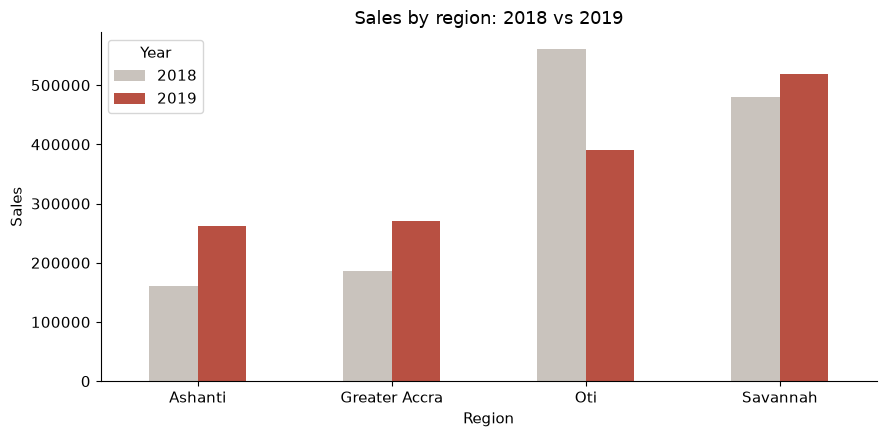

In [27]:
region_year[[2018, 2019]].plot(kind="bar", color=[GREY, MAIN])
plt.title("Sales by region: 2018 vs 2019")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG + "q5_region_yoy.png", dpi=150)
plt.show()

**Finding:** Savannah (35.3%) and Oti (33.6%) together make up 68.9% of sales. But Oti fell 30.5% in 2019 (561.2K to 389.9K), while Ashanti grew +62.7% and Greater Accra +45.4%.

**Recommendation:** Treat Oti as the priority region for 2020. The decline is concentrated in one area, so it can be fixed (see Q6). Keep investing in Ashanti and Greater Accra, where momentum is strong.

### Q6. What explains the Oti decline? Which salespeople grew or declined?

In [28]:
# Which reps sell in Oti, and how did each change?
oti = df[df["Region"] == "Oti"].pivot_table(index="Salesperson", columns="Year", values="Sales", aggfunc="sum")
oti.round(0)

Year,2018,2019
Salesperson,,
"Azpilecueta, Moses",44395.0,117762.0
"Smith, Bob",180962.0,63167.0
"Stuart, Jill",155486.0,206951.0
"Temple, Cheryl",180318.0,2028.0


In [29]:
# Every rep: sales per year, growth, and date of their last sale
rep_year = df.pivot_table(index="Salesperson", columns="Year", values="Sales", aggfunc="sum")
rep_year["Growth_%"] = (rep_year[2019] / rep_year[2018] - 1) * 100
rep_year["LastSale"] = df.groupby("Salesperson")["Date"].max()
rep_year.sort_values("Growth_%").round(1)

C:\Users\danie\AppData\Local\Temp\ipykernel_46316\2906054713.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  rep_year.sort_values("Growth_%").round(1)


Year,2018,2019,Growth_%,LastSale
Salesperson,,,,
"Temple, Cheryl",180318.1,2027.6,-98.9,2019-01-18
"Smith, Bob",180962.0,63166.5,-65.1,2019-09-09
"Barkley, Ross",116951.3,87877.1,-24.9,2019-12-24
"Read, Tira",189434.9,154980.6,-18.2,2019-12-24
"Dede, Amakye",131209.8,110473.3,-15.8,2019-10-07
"Haveria, Luiz",111493.8,140727.0,26.2,2019-12-25
"Stuart, Jill",155485.8,206950.7,33.1,2019-12-30
"Hines, Zach",84080.8,117927.7,40.3,2019-12-24
"Fog, Londong",77398.0,144812.0,87.1,2019-12-30


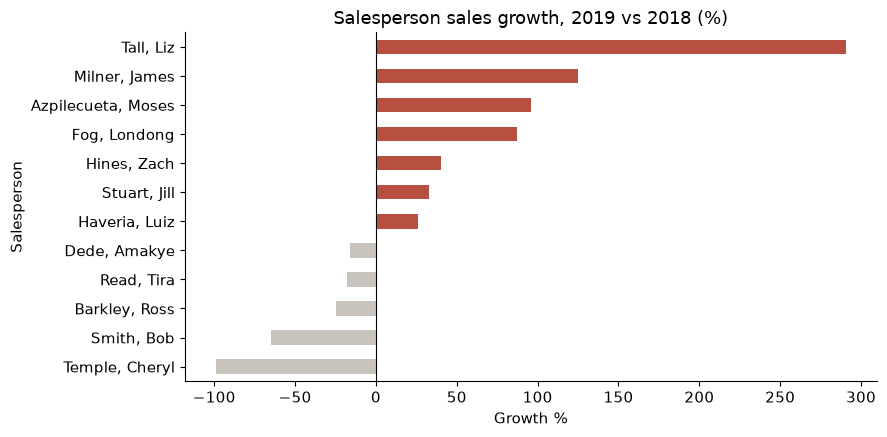

In [30]:
growth = rep_year["Growth_%"].sort_values()
colors = [MAIN if g > 0 else GREY for g in growth]
growth.plot(kind="barh", color=colors)
plt.title("Salesperson sales growth, 2019 vs 2018 (%)")
plt.xlabel("Growth %")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig(IMG + "q6_rep_yoy.png", dpi=150)
plt.show()

**Finding:** Two Oti reps account for the drop. Temple, Cheryl went from 180.3K to 2.0K (last sale 2019-01-18, only 5 orders in 2019). Smith, Bob fell 65.1% (last sale 2019-09-09). Other Oti reps recovered only part of the loss. Tall, Liz (+290.4%) and Milner, James (+124.9%) grew fastest.

**Recommendation:** When a rep leaves or goes quiet, reassign their customers within 30 days. Add a 'days since last sale' check per rep to the monthly dashboard so this shows up early.

### Q7. How dependent are we on a few customers?

In [31]:
# Customer sales, share, transactions and average order
cust = df.groupby("Customer").agg(Sales=("Sales", "sum"), Orders=("Sales", "count"))
cust["Share_%"] = cust["Sales"] / cust["Sales"].sum() * 100
cust["AvgOrder"] = cust["Sales"] / cust["Orders"]
cust = cust.sort_values("Sales", ascending=False)
cust.round(1)

,Sales,Orders,Share_%,AvgOrder
Customer,,,,
Elton John,917507.0,193,32.4,4753.9
Kwaku Mason,501135.6,188,17.7,2665.6
Clifford Quist,478552.6,181,16.9,2643.9
Fisher Mills,470054.9,175,16.6,2686.0
Sharon Sticks,464415.5,172,16.4,2700.1


In [32]:
# What does the biggest customer buy? (% of their spend by product)
top = cust.index[0]
(df[df["Customer"] == top].groupby("Product")["Sales"].sum() / cust.loc[top, "Sales"] * 100).round(1)

Product
Beef Meals            9.5
Fish Meals           19.1
Pasta Dishes         50.2
Seafood               3.9
Vegetarian Dishes    17.4
Name: Sales, dtype: float64

In [33]:
# Average order of the other four customers
round(df[df["Customer"] != top]["Sales"].mean(), 2)

np.float64(2673.41)

In [34]:
# Customer change 2018 -> 2019
cy = df.pivot_table(index="Customer", columns="Year", values="Sales", aggfunc="sum")
((cy[2019] / cy[2018] - 1) * 100).round(1)

Customer
Clifford Quist    -8.3
Elton John        -0.3
Fisher Mills       0.7
Kwaku Mason       12.4
Sharon Sticks     21.3
dtype: float64

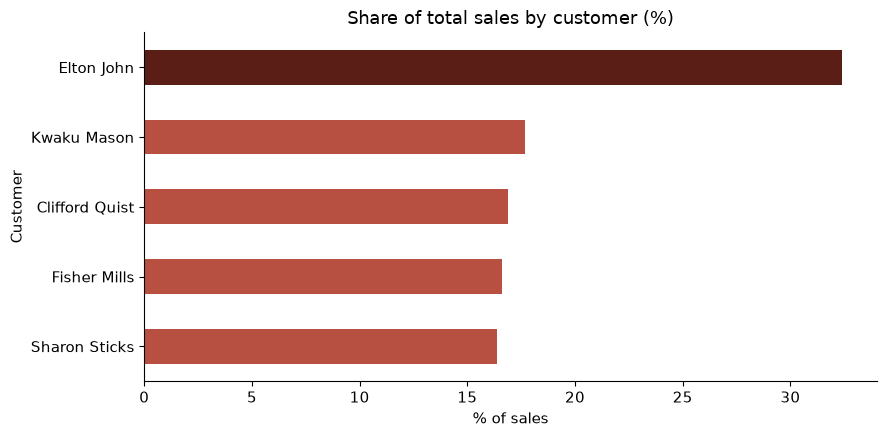

In [35]:
colors = [HIGHLIGHT] + [MAIN] * (len(cust) - 1)
cust["Share_%"].sort_values().plot(kind="barh", color=colors[::-1])
plt.title("Share of total sales by customer (%)")
plt.xlabel("% of sales")
plt.tight_layout()
plt.savefig(IMG + "q7_customer_share.png", dpi=150)
plt.show()

**Finding:** Elton John buys 32.4% of all sales (917.5K), almost twice the next customer. This customer's average order is 4,754 vs 2,673 for the other four, and 50.2% of their spend is pasta. Their spend was flat (-0.3%). Sharon Sticks grew most (+21.3%).

**Recommendation:** Give Elton John a named account manager and a retention offer, since losing them would cut about a third of sales. Cross-sell pasta to the other four customers to reduce the dependence.

### Q8. Who are the top salespeople, and what makes them top?

In [36]:
# Salesperson totals, orders and average order
rep = df.groupby("Salesperson").agg(Sales=("Sales", "sum"), Orders=("Sales", "count"))
rep["AvgOrder"] = rep["Sales"] / rep["Orders"]
rep["Share_%"] = rep["Sales"] / rep["Sales"].sum() * 100
rep = rep.sort_values("Sales", ascending=False)
rep.round(1)

,Sales,Orders,AvgOrder,Share_%
Salesperson,,,,
"Stuart, Jill",362436.6,119,3045.7,12.8
"Read, Tira",344415.5,96,3587.7,12.2
"Haveria, Luiz",252220.8,100,2522.2,8.9
"Smith, Bob",244128.6,84,2906.3,8.6
"Dede, Amakye",241683.0,78,3098.5,8.5
"Fog, Londong",222209.9,73,3044.0,7.8
"Azpilecueta, Moses",209208.8,71,2946.6,7.4
"Tall, Liz",207709.4,52,3994.4,7.3
"Barkley, Ross",204828.4,65,3151.2,7.2


In [37]:
# Is a rep's total driven by MORE orders or BIGGER orders?
print("Correlation sales vs number of orders:", round(rep["Sales"].corr(rep["Orders"]), 2))
print("Correlation sales vs average order:   ", round(rep["Sales"].corr(rep["AvgOrder"]), 2))
print("Top rep / bottom rep:", round(rep["Sales"].iloc[0] / rep["Sales"].iloc[-1], 2))

Correlation sales vs number of orders: 0.9
Correlation sales vs average order:    0.06
Top rep / bottom rep: 2.29


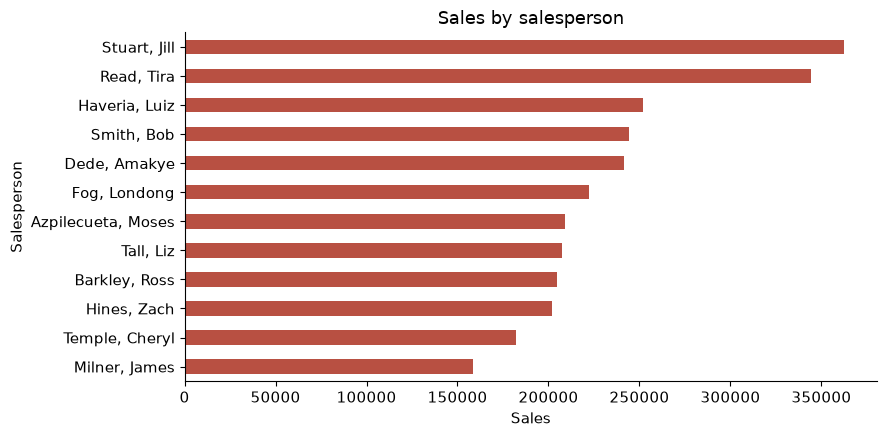

In [38]:
rep["Sales"].sort_values().plot(kind="barh", color=MAIN)
plt.title("Sales by salesperson")
plt.xlabel("Sales")
plt.tight_layout()
plt.savefig(IMG + "q8_rep_revenue.png", dpi=150)
plt.show()

**Finding:** Stuart, Jill (362.4K) and Read, Tira (344.4K) lead with 25.0% of sales together. The top rep sells 2.29x the bottom rep (Milner, James, 158.5K). Rep sales track the number of orders (correlation 0.90), not order size (0.06).

**Recommendation:** Coach on activity, meaning more customer contacts and more orders, rather than on upselling. Pair low-order reps with Stuart, Jill for call planning.

### Q9. What size are typical orders, and where does the money come from?

In [39]:
# Group orders into size bands by number of dishes
df["SizeBand"] = pd.cut(df["Units"], bins=[0, 5, 10, 15, 20], labels=["1-5", "6-10", "11-15", "16-20"])
bands = df.groupby("SizeBand", observed=False).agg(Orders=("Sales", "count"), Sales=("Sales", "sum"))
bands["Orders_%"] = bands["Orders"] / bands["Orders"].sum() * 100
bands["Sales_%"] = bands["Sales"] / bands["Sales"].sum() * 100
bands.round(1)

,Orders,Sales,Orders_%,Sales_%
SizeBand,,,,
1-5,257,254124.9,28.3,9.0
6-10,307,896989.1,33.8,31.7
11-15,280,1237994.7,30.8,43.7
16-20,65,442557.0,7.2,15.6


In [40]:
# Orders with 11+ dishes, and the top 20% of orders by value
big = df["Units"] >= 11
print("11+ dish orders:", big.sum(), "=", round(big.mean() * 100, 1), "% of orders,",
      round(df.loc[big, "Sales"].sum() / df["Sales"].sum() * 100, 1), "% of sales")
top20 = df["Sales"].sort_values(ascending=False).head(round(len(df) * 0.2))
print("Top 20% of orders:", len(top20), "orders =", round(top20.sum() / df["Sales"].sum() * 100, 1), "% of sales")
print("Median order:", df["Sales"].median(), " Largest:", df["Sales"].max())

11+ dish orders: 345 = 38.0 % of orders, 59.3 % of sales
Top 20% of orders: 182 orders = 52.6 % of sales
Median order: 2045.7  Largest: 15999.0


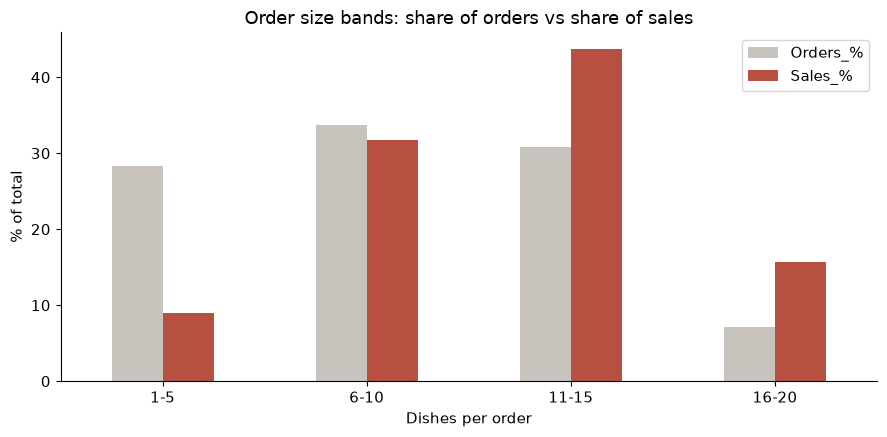

In [41]:
bands[["Orders_%", "Sales_%"]].plot(kind="bar", color=[GREY, MAIN])
plt.title("Order size bands: share of orders vs share of sales")
plt.xlabel("Dishes per order")
plt.ylabel("% of total")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG + "q9_order_size.png", dpi=150)
plt.show()

**Finding:** Orders range from 1 to 20 dishes (median order 2,045.70). Orders of 11+ dishes are 38.0% of orders but 59.3% of sales. Small orders (1-5 dishes) are 28.3% of orders and only 9.0% of sales.

**Recommendation:** Introduce a volume deal at 11+ dishes (for example, a free side) to move 6-10 dish orders up a band. Handle 1-5 dish orders through a low-cost channel.

### Q10. Which days of the week do orders come in?

In [42]:
# Orders and sales by day of the week
day_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
days = df.groupby("Weekday").agg(Orders=("Sales", "count"), Sales=("Sales", "sum")).reindex(day_order)
days["Orders_%"] = days["Orders"] / days["Orders"].sum() * 100
days["Sales_%"] = days["Sales"] / days["Sales"].sum() * 100
days.round(1)

,Orders,Sales,Orders_%,Sales_%
Weekday,,,,
Mon,271,792346.2,29.8,28.0
Tue,131,468630.4,14.4,16.5
Wed,118,347148.9,13.0,12.3
Thu,138,433733.0,15.2,15.3
Fri,128,437036.0,14.1,15.4
Sat,2,3750.4,0.2,0.1
Sun,121,349020.7,13.3,12.3


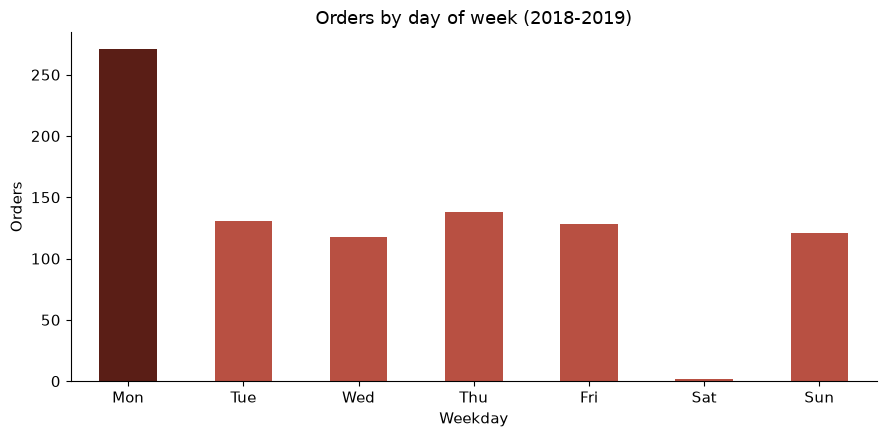

In [43]:
colors = [HIGHLIGHT if d == "Mon" else MAIN for d in days.index]
days["Orders"].plot(kind="bar", color=colors)
plt.title("Orders by day of week (2018-2019)")
plt.ylabel("Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(IMG + "q10_weekday.png", dpi=150)
plt.show()

**Finding:** Monday is the busiest day by far: 271 orders (29.8%) and 28.0% of sales. The other weekdays and Sunday get 118-138 orders each. Saturday has only 2 orders in two years, so the business is effectively closed on Saturdays.

**Recommendation:** Staff and prep for Monday as the peak day. Consider a Saturday offer or confirm the closure. Check whether Monday orders are weekend demand booked late, and smooth it with pre-orders.

## Summary
- **Q1 Overall performance & growth:** Growth is slow and comes from bigger orders, not more orders. Set a 2020 target for order count (for example +5%) and track orders and average order value as separate KPIs.
- **Q2 Monthly seasonality:** Do not plan staffing or stock from a single 'seasonality' chart that merges years. Plan month by month from a rolling forecast, and only lock in a Nov-Dec uplift, the one pattern seen in both years.
- **Q3 Product revenue vs volume:** Protect pasta availability and quality first; it is nearly half the business. Use Seafood as a low-price add-on or review its price, since its volume is not turning into revenue.
- **Q4 Product growth:** Put promotion budget behind Beef and Pasta, which are already growing. Run a short review of the Seafood menu (price, portion, visibility) before cutting it.
- **Q5 Regional performance:** Treat Oti as the priority region for 2020. The decline is concentrated in one area, so it can be fixed (see Q6). Keep investing in Ashanti and Greater Accra, where momentum is strong.
- **Q6 Why Oti declined:** When a rep leaves or goes quiet, reassign their customers within 30 days. Add a 'days since last sale' check per rep to the monthly dashboard so this shows up early.
- **Q7 Customer concentration:** Give Elton John a named account manager and a retention offer, since losing them would cut about a third of sales. Cross-sell pasta to the other four customers to reduce the dependence.
- **Q8 Salesperson performance:** Coach on activity, meaning more customer contacts and more orders, rather than on upselling. Pair low-order reps with Stuart, Jill for call planning.
- **Q9 Order size:** Introduce a volume deal at 11+ dishes (for example, a free side) to move 6-10 dish orders up a band. Handle 1-5 dish orders through a low-cost channel.
- **Q10 Day of week:** Staff and prep for Monday as the peak day. Consider a Saturday offer or confirm the closure. Check whether Monday orders are weekend demand booked late, and smooth it with pre-orders.